<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates Lab**


Estimated time needed: **30** minutes


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


In [4]:
!pip install pandas
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 155.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 156.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 150.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 157.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


Import pandas module


In [5]:
import pandas as pd


Import matplotlib


In [6]:
import matplotlib.pyplot as plt


## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


In [7]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [8]:
# df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")


## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [9]:
## Write your code here
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display the first few duplicate rows
duplicates = df[df.duplicated()]

print("\nFirst few duplicate rows:")
print(duplicates.head())

Number of duplicate rows: 20
First few duplicate rows:
       ResponseId                      MainBranch                 Age  \
65437           1  I am a developer by profession  Under 18 years old   
65438           2  I am a developer by profession     35-44 years old   
65439           3  I am a developer by profession     45-54 years old   
65440           4           I am learning to code     18-24 years old   
65441           5  I am a developer by profession     18-24 years old   

                Employment RemoteWork   Check  \
65437  Employed, full-time     Remote  Apples   
65438  Employed, full-time     Remote  Apples   
65439  Employed, full-time     Remote  Apples   
65440   Student, full-time        NaN  Apples   
65441   Student, full-time        NaN  Apples   

                                        CodingActivities  \
65437                                              Hobby   
65438  Hobby;Contribute to open-source projects;Other...   
65439  Hobby;Contribute to open

### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   


In [14]:
## Write your code here
# Group respondents based on MainBranch, Employment, and RemoteWork
response_patterns = (
    df.groupby(["MainBranch", "Employment", "RemoteWork"])
      .size()
      .reset_index(name="Count")
)

# Display the 10 most common response patterns
print("Most common response patterns:")
print(response_patterns.sort_values("Count", ascending=False).head(10))

# Analyze which other columns frequently have identical values
pattern_columns = ["MainBranch", "Employment", "RemoteWork"]

# Keep only response-pattern groups containing more than one respondent
pattern_groups = df.groupby(pattern_columns)

other_columns = [col for col in df.columns if col not in pattern_columns]

# For each other column, count how many response-pattern groups
# have the same value for every respondent in that group.
shared_value_summary = []

for col in other_columns:
    identical_groups = 0
    total_groups = 0

    for _, group in pattern_groups:
        if len(group) > 1:
            non_null_values = group[col].dropna()
            if len(non_null_values) > 0:
                total_groups += 1
                if non_null_values.nunique() == 1:
                    identical_groups += 1

    percentage = (
        identical_groups / total_groups * 100
        if total_groups > 0 else 0
    )

    shared_value_summary.append(
        [col, identical_groups, total_groups, percentage]
    )

shared_value_summary = pd.DataFrame(
    shared_value_summary,
    columns=["Column", "Groups with Identical Values",
             "Groups Checked", "Percentage"]
)

print("\nOther columns that frequently share identical values:")
print(
    shared_value_summary
    .sort_values("Percentage", ascending=False)
    .head(10)
    .to_string(index=False)
)

Most common response patterns:
                                            MainBranch  \
0                       I am a developer by profession   
2                       I am a developer by profession   
1                       I am a developer by profession   
78                      I am a developer by profession   
8                       I am a developer by profession   
232  I am not primarily a developer, but I write co...   
6                       I am a developer by profession   
76                      I am a developer by profession   
233  I am not primarily a developer, but I write co...   
234  I am not primarily a developer, but I write co...   

                                            Employment  \
0                                  Employed, full-time   
2                                  Employed, full-time   
1                                  Employed, full-time   
78   Independent contractor, freelancer, or self-em...   
8    Employed, full-time;Independent con

### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


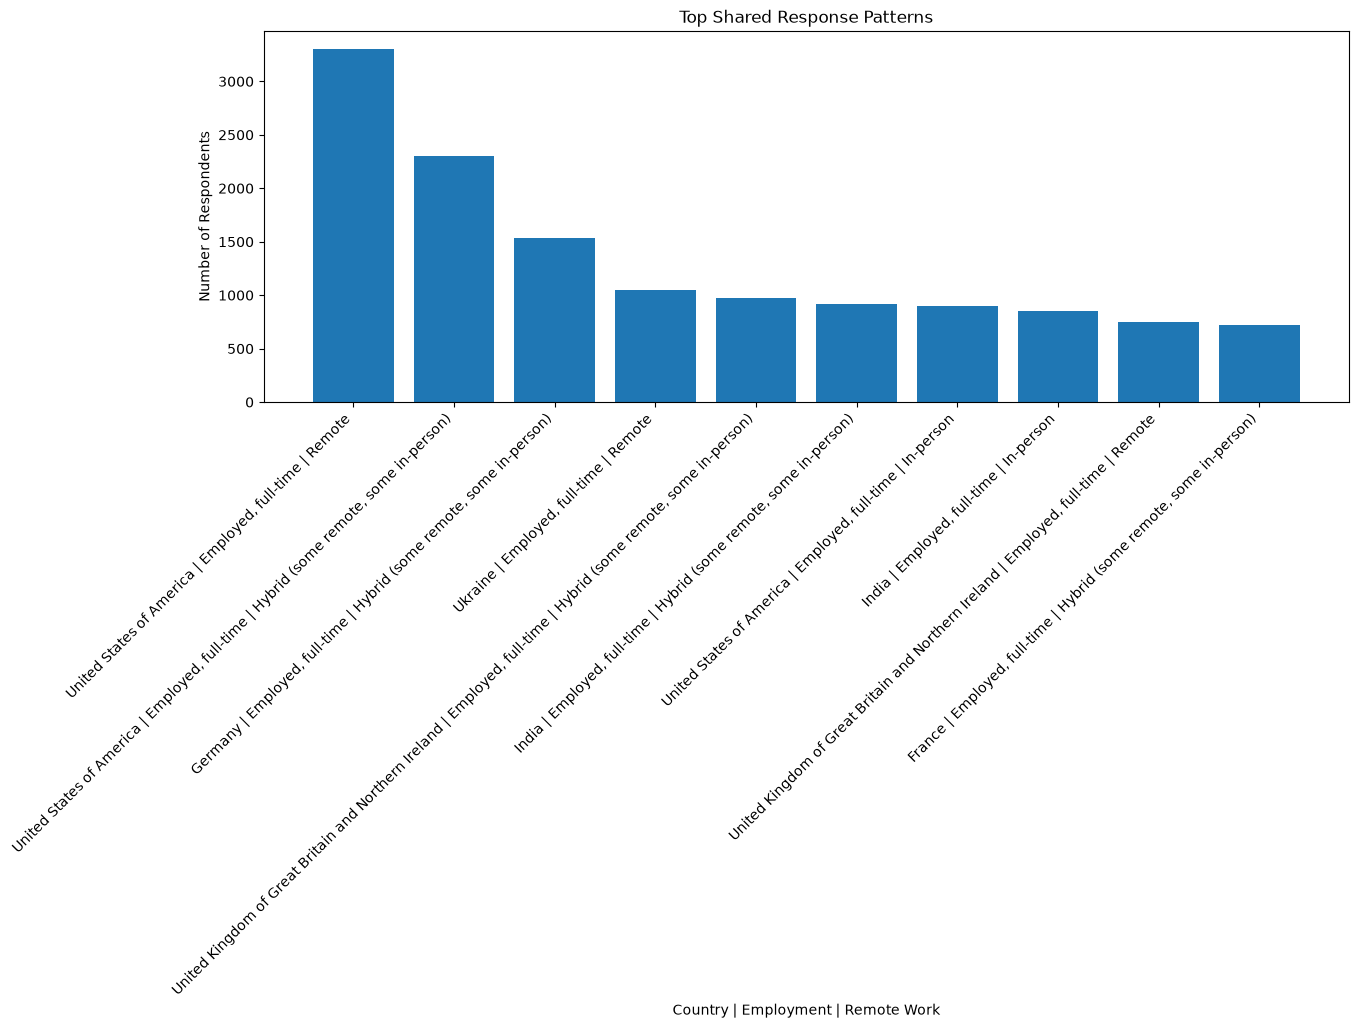

In [13]:
## Write your code here
# Count shared response patterns by Country and Employment
pattern_counts = (
    df.groupby(["Country", "Employment", "MainBranch", "RemoteWork"])
      .size()
      .reset_index(name="Count")
)

# Select the 10 most common response patterns
top_patterns = pattern_counts.sort_values(
    "Count", ascending=False
).head(10)

# Create labels
top_patterns["Pattern"] = (
    top_patterns["Country"] + " | " +
    top_patterns["Employment"] + " | " +
    top_patterns["RemoteWork"]
)

# Create bar chart
plt.figure(figsize=(14, 7))

plt.bar(top_patterns["Pattern"], top_patterns["Count"])

plt.xlabel("Country | Employment | Remote Work")
plt.ylabel("Number of Respondents")
plt.title("Top Shared Response Patterns")

plt.xticks(rotation=45, ha="right")

plt.subplots_adjust(bottom=0.35)

plt.show()

### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


In [15]:
print("Total rows:", len(df))
print("Unique ResponseId values:", df["ResponseId"].nunique())
print("Duplicate ResponseId values:", df["ResponseId"].duplicated().sum())

Total rows: 65457
Unique ResponseId values: 65437
Duplicate ResponseId values: 20

The ResponseId column is intended to identify an individual survey response. Its uniqueness should be verified before using it as the record identifier. MainBranch, Employment, and RemoteWork should not be used alone to identify duplicate records because different respondents can legitimately have the same answers to these questions.

Therefore, removing rows based only on a subset of response columns is not appropriate. Doing so could remove valid responses from different respondents who happen to have identical response patterns. Exact duplicate records should be identified using all columns, while duplicate respondent identifiers should be checked separately using ResponseId. This approach preserves valid survey responses while removing only records that are genuinely duplicated.


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
